TASK 1:DATA PREPARATION



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
 #Import libraries and load dataset


import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

# Download dataset
url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
zip_file = "household_power_consumption.zip"
dataset_file = "household_power_consumption.txt"

if not os.path.exists(dataset_file):
    if not os.path.exists(zip_file):
        print("Downloading dataset...")
        urllib.request.urlretrieve(url, zip_file)

    with zipfile.ZipFile(zip_file, "r") as z:
        z.extractall(".")

# Load dataset
df = pd.read_csv(
    dataset_file,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Original dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Original dataset shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [ ]:
#Clean and preprocess data


# Convert Date and Time into a datetime column
df["Datetime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

# Convert power consumption to numeric
df["Global_active_power"] = pd.to_numeric(
    df["Global_active_power"],
    errors="coerce"
)

# Select required columns
df = df[["Datetime", "Global_active_power"]]

# Remove invalid timestamps and sort
df = df.dropna(subset=["Datetime"])
df = df.sort_values("Datetime")
df = df.set_index("Datetime")

# Handle missing values
df["Global_active_power"] = (
    df["Global_active_power"]
    .interpolate(method="time", limit_area="inside")
    .ffill()
    .bfill()
)

print("Missing values after cleaning:")
print(df.isnull().sum())

print("Cleaned dataset shape:", df.shape)
display(df.head())

Missing values after cleaning:
Global_active_power    0
dtype: int64
Cleaned dataset shape: (2075259, 1)


,Global_active_power
Datetime,
2006-12-16 17:24:00,4.216
2006-12-16 17:25:00,5.360
2006-12-16 17:26:00,5.374
2006-12-16 17:27:00,5.388
2006-12-16 17:28:00,3.666


Hourly dataset shape: (34589, 1)


,Global_active_power
Datetime,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467


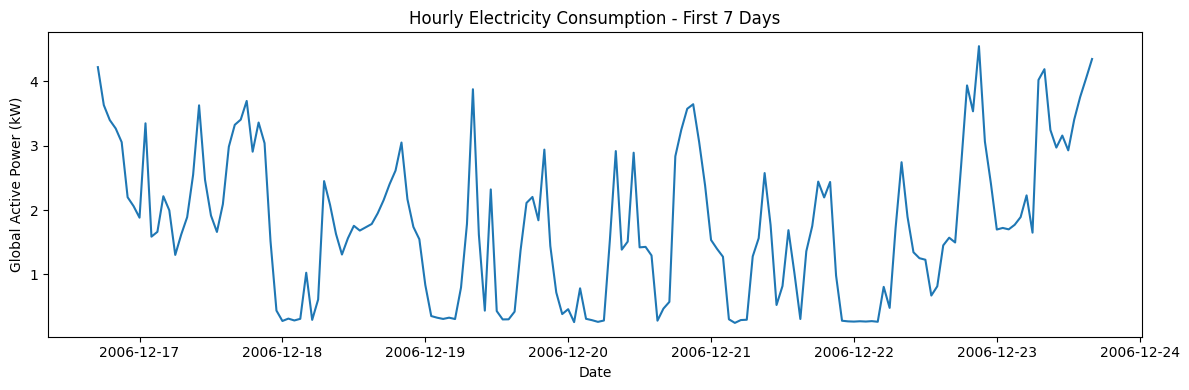

In [ ]:
#Resample to hourly data


# Convert minute-level readings to hourly averages
hourly_df = df.resample("h").mean()

hourly_df["Global_active_power"] = (
    hourly_df["Global_active_power"]
    .interpolate(method="time")
    .ffill()
    .bfill()
)

print("Hourly dataset shape:", hourly_df.shape)
display(hourly_df.head())

plt.figure(figsize=(12, 4))
plt.plot(
    hourly_df.index[:168],
    hourly_df["Global_active_power"].iloc[:168]
)
plt.title("Hourly Electricity Consumption - First 7 Days")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.tight_layout()
plt.show()

In [ ]:
#Normalize the data

# Select the target feature
data = hourly_df[["Global_active_power"]].values.astype(np.float32)

# Split chronologically: 80% training, 20% testing
split_index = int(len(data) * 0.80)
train_data = data[:split_index]

# Fit scaler only on training data
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_data)

scaled_data = scaler.transform(data).astype(np.float32)

print("Total observations:", len(data))
print("Training observations:", split_index)
print("Testing observations:", len(data) - split_index)
print("Normalization completed!")
print("First 5 normalized values:")
print(scaled_data[:5])

Total observations: 34589
Training observations: 27671
Testing observations: 6918
Normalization completed!
First 5 normalized values:
[[0.6368162 ]
 [0.5450449 ]
 [0.50900584]
 [0.48854968]
 [0.4555972 ]]


In [ ]:
#Create time-series sequences

#The model uses the previous 24 hours to predict electricity consumption for the next hour.

sequence_length = 24

X_all = []
y_all = []
target_indices = []

for i in range(sequence_length, len(scaled_data)):
    X_all.append(scaled_data[i-sequence_length:i])
    y_all.append(scaled_data[i])
    target_indices.append(i)

X_all = np.asarray(X_all, dtype=np.float32)
y_all = np.asarray(y_all, dtype=np.float32)
target_indices = np.asarray(target_indices)

# Split sequences according to target time
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X_all[train_mask]
y_train = y_all[train_mask]

X_test = X_all[test_mask]
y_test = y_all[test_mask]

print("========== TASK 1 OUTPUT ==========")
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Sequence length:", sequence_length)
print("Task 1 completed successfully!")

========== TASK 1 OUTPUT ==========
X_train shape: (27647, 24, 1)
y_train shape: (27647, 1)
X_test shape: (6918, 24, 1)
y_test shape: (6918, 1)
Sequence length: 24
Task 1 completed successfully!


TASK 2:RNN MODEL DEVELOPMENT

In [ ]:
#Build and compile the RNN model


import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Set random seed
tf.random.set_seed(42)

# Build RNN model
rnn_model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    SimpleRNN(32, activation="tanh"),
    Dropout(0.1),
    Dense(16, activation="relu"),
    Dense(1)
])

# Compile the model
rnn_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Display model architecture
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,633 (6.38 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train the RNN model



# Stop training if validation loss does not improve
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the model
history_rnn = rnn_model.fit(
    X_train,
    y_train,
    epochs=8,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("RNN model training completed successfully!")

Epoch 1/8
389/389 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.0119 - mae: 0.0776 - val_loss: 0.0093 - val_mae: 0.0703
Epoch 2/8
389/389 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0092 - mae: 0.0673 - val_loss: 0.0095 - val_mae: 0.0710
Epoch 3/8
389/389 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0090 - mae: 0.0661 - val_loss: 0.0094 - val_mae: 0.0702
RNN model training completed successfully!


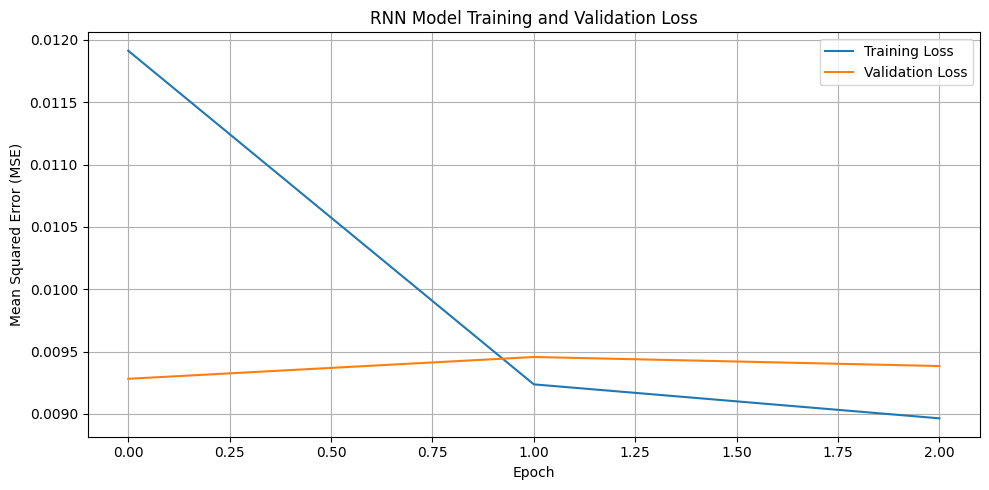

In [ ]:
#Display the training output graph


plt.figure(figsize=(10, 5))

plt.plot(
    history_rnn.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_rnn.history["val_loss"],
    label="Validation Loss"
)

plt.title("RNN Model Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#Evaluate the RNN model

# Evaluate on test data
test_loss, test_mae = rnn_model.evaluate(
    X_test, y_test, verbose=0
)

print("========== RNN EVALUATION ==========")
print("Test Loss (MSE):", round(test_loss, 6))
print("Test MAE (normalized scale):", round(test_mae, 6))

# Generate predictions
rnn_predictions_scaled = rnn_model.predict(
    X_test, verbose=0
)

print("Predictions shape:", rnn_predictions_scaled.shape)
print("RNN Task 2 completed successfully!")

========== RNN EVALUATION ==========
Test Loss (MSE): 0.006568
Test MAE (normalized scale): 0.061212
Predictions shape: (6918, 1)
RNN Task 2 completed successfully!


TASK 3:LSTM MODEL DEVELOPMENT

In [ ]:
 #Build and compile the LSTM model



from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Build LSTM model
lstm_model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(32, activation="tanh"),
    Dropout(0.1),
    Dense(16, activation="relu"),
    Dense(1)
])

# Compile model
lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Display model architecture
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
 #Train the LSTM model


early_stop_lstm = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_lstm = lstm_model.fit(
    X_train,
    y_train,
    epochs=8,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop_lstm],
    verbose=1
)

print("LSTM model training completed successfully!")

Epoch 1/8
389/389 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.0157 - mae: 0.0929 - val_loss: 0.0125 - val_mae: 0.0828
Epoch 2/8
389/389 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0107 - mae: 0.0743 - val_loss: 0.0108 - val_mae: 0.0762
Epoch 3/8
389/389 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 0.0098 - mae: 0.0700 - val_loss: 0.0105 - val_mae: 0.0743
Epoch 4/8
389/389 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0096 - mae: 0.0687 - val_loss: 0.0106 - val_mae: 0.0747
Epoch 5/8
389/389 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.0096 - mae: 0.0685 - val_loss: 0.0106 - val_mae: 0.0748
LSTM model training completed successfully!


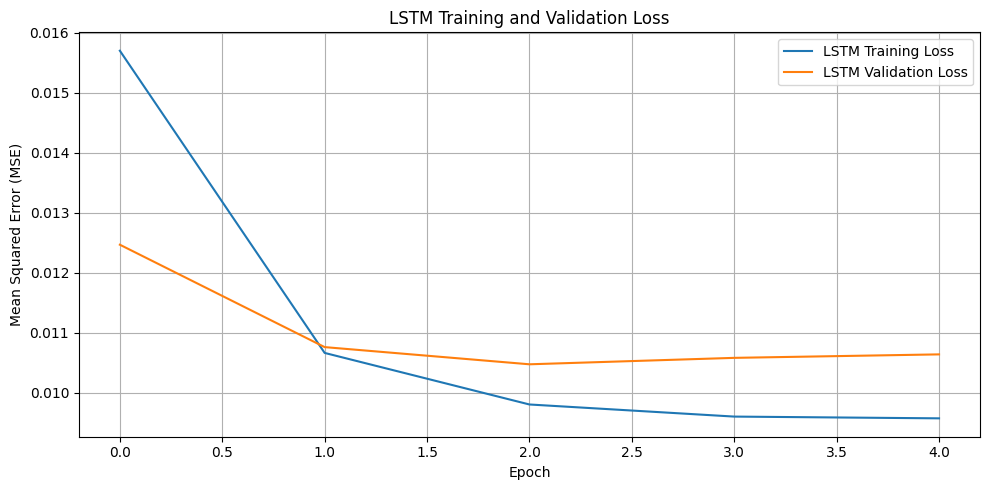

In [ ]:
#Plot training and validation loss


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_lstm.history["loss"],
    label="LSTM Training Loss"
)

plt.plot(
    history_lstm.history["val_loss"],
    label="LSTM Validation Loss"
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
#Compare LSTM with RNN


# Evaluate both models on the same test dataset
rnn_loss, rnn_mae = rnn_model.evaluate(
    X_test, y_test, verbose=0
)

lstm_loss, lstm_mae = lstm_model.evaluate(
    X_test, y_test, verbose=0
)

comparison = pd.DataFrame({
    "Model": ["RNN", "LSTM"],
    "Test MSE": [rnn_loss, lstm_loss],
    "Test MAE (normalized)": [rnn_mae, lstm_mae]
})

print("RNN vs LSTM Comparison")
display(comparison.round(5))

if lstm_loss < rnn_loss:
    print("LSTM achieved lower test MSE in this run.")
elif rnn_loss < lstm_loss:
    print("RNN achieved lower test MSE in this run.")
else:
    print("Both models achieved equal test MSE.")

RNN vs LSTM Comparison


,Model,Test MSE,Test MAE (normalized)
0,RNN,0.00657,0.06121
1,LSTM,0.00722,0.06547


RNN achieved lower test MSE in this run.


TASK 4: MODEL EVALUATION





In [ ]:
#Predict using both models

# Task 4: Generate predictions from both models

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error

# Predict test data
rnn_pred_scaled = rnn_model.predict(X_test, verbose=0)
lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)

# Convert normalized values back to original kW scale
actual = scaler.inverse_transform(y_test)
rnn_pred = scaler.inverse_transform(rnn_pred_scaled)
lstm_pred = scaler.inverse_transform(lstm_pred_scaled)

print("RNN predictions shape:", rnn_pred.shape)
print("LSTM predictions shape:", lstm_pred.shape)
print("Actual values shape:", actual.shape)
print("Predictions generated successfully!")

RNN predictions shape: (6918, 1)
LSTM predictions shape: (6918, 1)
Actual values shape: (6918, 1)
Predictions generated successfully!


In [ ]:
#Calculate RMSE and MAE


# Calculate performance metrics

rnn_rmse = np.sqrt(mean_squared_error(actual, rnn_pred))
rnn_mae = mean_absolute_error(actual, rnn_pred)

lstm_rmse = np.sqrt(mean_squared_error(actual, lstm_pred))
lstm_mae = mean_absolute_error(actual, lstm_pred)

results = pd.DataFrame({
    "Model": ["RNN", "LSTM"],
    "RMSE (kW)": [rnn_rmse, lstm_rmse],
    "MAE (kW)": [rnn_mae, lstm_mae]
})

print("========== TASK 4: MODEL EVALUATION ==========")
display(results.round(4))

========== TASK 4: MODEL EVALUATION ==========


,Model,RMSE (kW),MAE (kW)
0,RNN,0.5217,0.3940
1,LSTM,0.5469,0.4214


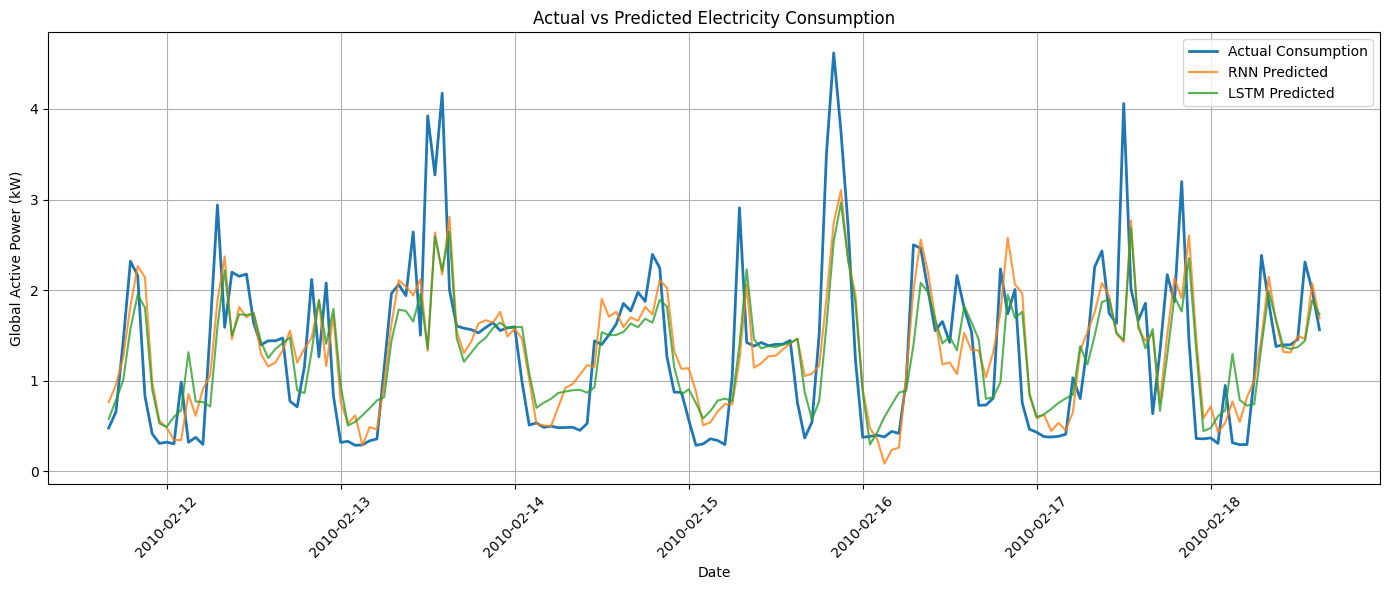

Task 4 graph generated successfully!


In [ ]:


# Task 4: Actual vs Predicted Electricity Consumption

import numpy as np
import matplotlib.pyplot as plt

# Number of test observations to display (maximum 7 days)
plot_count = min(168, len(actual))

# Create timestamps directly from the test dataset
test_dates = hourly_df.index[-len(actual):][:plot_count]

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    actual[:plot_count].ravel(),
    label="Actual Consumption",
    linewidth=2
)

plt.plot(
    test_dates,
    rnn_pred[:plot_count].ravel(),
    label="RNN Predicted",
    alpha=0.8
)

plt.plot(
    test_dates,
    lstm_pred[:plot_count].ravel(),
    label="LSTM Predicted",
    alpha=0.8
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Task 4 graph generated successfully!")

In [ ]:
#Identify the better-performing model


print("========== PERFORMANCE SUMMARY ==========")

print(f"RNN  RMSE: {rnn_rmse:.4f} kW")
print(f"RNN  MAE:  {rnn_mae:.4f} kW")
print(f"LSTM RMSE: {lstm_rmse:.4f} kW")
print(f"LSTM MAE:  {lstm_mae:.4f} kW")

if rnn_rmse < lstm_rmse:
    print("\nRNN has lower RMSE in this experiment.")
elif lstm_rmse < rnn_rmse:
    print("\nLSTM has lower RMSE in this experiment.")
else:
    print("\nBoth models have equal RMSE.")

print("\nTask 4 completed successfully!")

========== PERFORMANCE SUMMARY ==========
RNN  RMSE: 0.5217 kW
RNN  MAE:  0.3940 kW
LSTM RMSE: 0.5469 kW
LSTM MAE:  0.4214 kW

RNN has lower RMSE in this experiment.

Task 4 completed successfully!


TASK 5:PERFORMANCE ANALYSIS


In [ ]:
#Compare RNN and LSTM performance


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Generate predictions
rnn_pred_scaled = rnn_model.predict(X_test, verbose=0)
lstm_pred_scaled = lstm_model.predict(X_test, verbose=0)

# Convert predictions to original power consumption scale (kW)
actual_values = scaler.inverse_transform(y_test)
rnn_predictions = scaler.inverse_transform(rnn_pred_scaled)
lstm_predictions = scaler.inverse_transform(lstm_pred_scaled)

# Calculate performance metrics
rnn_rmse = np.sqrt(mean_squared_error(actual_values, rnn_predictions))
rnn_mae = mean_absolute_error(actual_values, rnn_predictions)

lstm_rmse = np.sqrt(mean_squared_error(actual_values, lstm_predictions))
lstm_mae = mean_absolute_error(actual_values, lstm_predictions)

# Display comparison table
comparison = pd.DataFrame({
    "Model": ["RNN", "LSTM"],
    "RMSE (kW)": [rnn_rmse, lstm_rmse],
    "MAE (kW)": [rnn_mae, lstm_mae]
})

print("RNN vs LSTM Performance Comparison")
display(comparison.round(4))

RNN vs LSTM Performance Comparison


,Model,RMSE (kW),MAE (kW)
0,RNN,0.5217,0.3940
1,LSTM,0.5469,0.4214


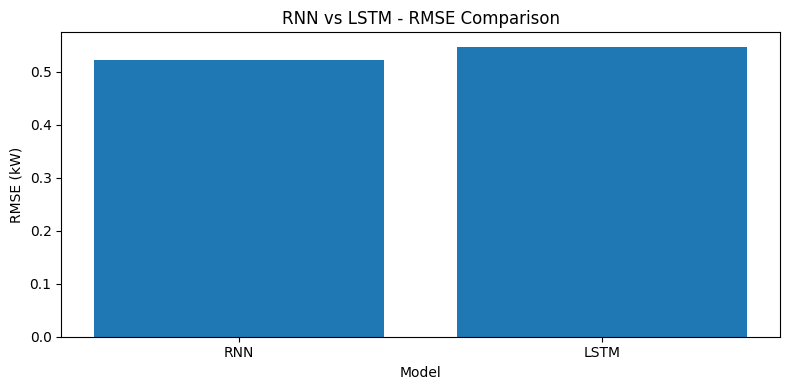

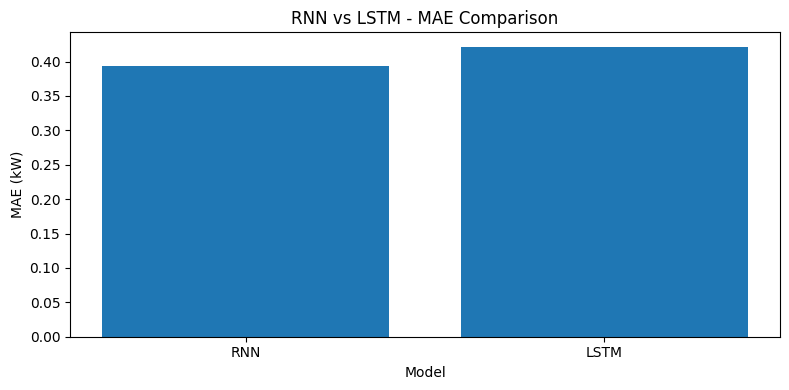

In [ ]:
#Plot the performance comparison


models = ["RNN", "LSTM"]

plt.figure(figsize=(8, 4))
plt.bar(models, [rnn_rmse, lstm_rmse])
plt.title("RNN vs LSTM - RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE (kW)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.bar(models, [rnn_mae, lstm_mae])
plt.title("RNN vs LSTM - MAE Comparison")
plt.xlabel("Model")
plt.ylabel("MAE (kW)")
plt.tight_layout()
plt.show()

In [ ]:
# Task 5: Vanishing Gradient Problem Analysis

print("VANISHING GRADIENT PROBLEM")
print("-" * 40)

print("""
1. The vanishing gradient problem occurs when gradients
   become very small during backpropagation.

2. A basic RNN may struggle to learn long-term dependencies
   in sequential data.

3. LSTM uses input, forget, and output gates to control
   information flow through its memory cells.

4. These gates help LSTM learn long-term patterns and
   reduce the effects of vanishing gradients.

5. Compare the RNN and LSTM RMSE and MAE values to determine
   which model performed better on the test dataset.
""")

print("RNN RMSE:", round(rnn_rmse, 4))
print("LSTM RMSE:", round(lstm_rmse, 4))
print("RNN MAE:", round(rnn_mae, 4))
print("LSTM MAE:", round(lstm_mae, 4))



VANISHING GRADIENT PROBLEM
----------------------------------------

1. The vanishing gradient problem occurs when gradients
   become very small during backpropagation.

2. A basic RNN may struggle to learn long-term dependencies
   in sequential data.

3. LSTM uses input, forget, and output gates to control
   information flow through its memory cells.

4. These gates help LSTM learn long-term patterns and
   reduce the effects of vanishing gradients.

5. Compare the RNN and LSTM RMSE and MAE values to determine
   which model performed better on the test dataset.

RNN RMSE: 0.5217
LSTM RMSE: 0.5469
RNN MAE: 0.394
LSTM MAE: 0.4214


In [ ]:
#Print the conclusion


print("========== TASK 5: PERFORMANCE ANALYSIS ==========")

if rnn_rmse < lstm_rmse:
    print("RNN achieved lower RMSE in this experiment.")
elif lstm_rmse < rnn_rmse:
    print("LSTM achieved lower RMSE in this experiment.")
else:
    print("Both models achieved equal RMSE.")

if rnn_mae < lstm_mae:
    print("RNN has lower mean absolute error.")
elif lstm_mae < rnn_mae:
    print("LSTM has lower mean absolute error.")
else:
    print("Both models achieved equal MAE.")

print("""
Analysis:
1. RMSE measures the square root of the average squared prediction error.
2. MAE measures the average absolute prediction error.
3. Lower RMSE and MAE indicate better prediction accuracy.
4. A basic RNN may suffer from the vanishing gradient problem,
   making long-term dependencies difficult to learn.
5. LSTM uses gated memory cells to help learn long-term dependencies.
6. LSTM is not guaranteed to perform better; compare the actual metrics.
""")

print("Task 5 completed successfully!")

========== TASK 5: PERFORMANCE ANALYSIS ==========
RNN achieved lower RMSE in this experiment.
RNN has lower mean absolute error.

Analysis:
1. RMSE measures the square root of the average squared prediction error.
2. MAE measures the average absolute prediction error.
3. Lower RMSE and MAE indicate better prediction accuracy.
4. A basic RNN may suffer from the vanishing gradient problem,
   making long-term dependencies difficult to learn.
5. LSTM uses gated memory cells to help learn long-term dependencies.
6. LSTM is not guaranteed to perform better; compare the actual metrics.

Task 5 completed successfully!
